<center><h1>Jha_Ria_HW7</h1></center>


Name: Ria Jha
<br>
Github Username: riajha-usc
<br>
USC ID: 8116906970


## 1. Multi-class and Multi-Label Classification Using Support Vector Machines


Import packages


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             roc_curve, balanced_accuracy_score, silhouette_score)
from sklearn.cluster import KMeans
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

### (a) Download the Anuran Calls (MFCCs) Data Set


In [2]:
import zipfile
from pathlib import Path

ZIP_PATH = "Homework 7 Data.zip"   
EXTRACT_DIR = "hw7_data"           

with zipfile.ZipFile(ZIP_PATH) as zf:
    csv_member = next(n for n in zf.namelist() if n.endswith("Frogs_MFCCs.csv"))
    zf.extract(csv_member, EXTRACT_DIR)

df = pd.read_csv(Path(EXTRACT_DIR) / csv_member)

feature_cols = list(df.columns[:22])
label_cols = ["Family", "Genus", "Species"]
X = df[feature_cols].values
Y = df[label_cols].values                                   

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.7, random_state=42, stratify=Y[:, 2])
print(df.shape, X_train.shape, X_test.shape)

(7195, 26) (5036, 22) (2159, 22)


### (b) Train a classifier for each label


#### (i) Research


- Exact match ratio (subset accuracy): the fraction of instances where all three labels are correct. It is the strictest metric, because one wrong label makes the whole instance wrong.
- Hamming distance (per instance): the number of labels where prediction and truth differ, so 0 to 3 here. Averaged over instances.
- Hamming loss: the fraction of wrong label slots, (1/(n·L)) Σ 1[y_ij ≠ ŷ_ij]. Here it equals mean Hamming distance / 3.
- Hamming score: 1 − Hamming loss, the fraction of correct label slots. Sorower’s survey also defines a set-based “accuracy” (Jaccard, |Y∩Z|/|Y∪Z|). Here each label slot holds exactly one class, so I use the slot-wise version.


In [3]:
def multilabel_scores(Y_true, Y_pred):
    mismatch = (np.asarray(Y_true) != np.asarray(Y_pred))
    return {"exact_match": np.mean(~mismatch.any(axis=1)),
            "hamming_distance": mismatch.sum(axis=1).mean(),
            "hamming_loss": mismatch.mean(),
            "hamming_score": 1 - mismatch.mean()}

#### (ii) Train a SVM for each of the labels


In [4]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
rbf_grid = {"clf__estimator__C": np.logspace(-1, 3, 5),
            "clf__estimator__gamma": np.logspace(-2, 1, 4)}

def rbf_pipe(standardize):
    steps = [("scaler", StandardScaler())] if standardize else []
    steps.append(("clf", OneVsRestClassifier(SVC(kernel="rbf"))))
    return Pipeline(steps)

rbf_models, rbf_pred, rows = {}, {}, []
for mode, std in [("raw", False), ("standardized", True)]:
    preds = np.empty_like(Y_test)
    for j, lab in enumerate(label_cols):
        gs = GridSearchCV(rbf_pipe(std), rbf_grid, cv=cv10, scoring="accuracy", n_jobs=-1)
        gs.fit(X_train, Y_train[:, j])
        rbf_models[(mode, lab)] = gs
        preds[:, j] = gs.predict(X_test)
        print(mode, lab, gs.best_params_, "CV acc:", round(gs.best_score_, 4))
    rbf_pred[mode] = preds
    rows.append({"model": f"RBF-SVM {mode}", **multilabel_scores(Y_test, preds)})
pd.DataFrame(rows).round(4)

raw Family {'clf__estimator__C': np.float64(1000.0), 'clf__estimator__gamma': np.float64(1.0)} CV acc: 0.9921
raw Genus {'clf__estimator__C': np.float64(1000.0), 'clf__estimator__gamma': np.float64(1.0)} CV acc: 0.9889
raw Species {'clf__estimator__C': np.float64(10.0), 'clf__estimator__gamma': np.float64(1.0)} CV acc: 0.9887
standardized Family {'clf__estimator__C': np.float64(100.0), 'clf__estimator__gamma': np.float64(0.01)} CV acc: 0.9899
standardized Genus {'clf__estimator__C': np.float64(10.0), 'clf__estimator__gamma': np.float64(0.1)} CV acc: 0.9885
standardized Species {'clf__estimator__C': np.float64(1000.0), 'clf__estimator__gamma': np.float64(0.01)} CV acc: 0.9871


,model,exact_match,hamming_distance,hamming_loss,hamming_score
0,RBF-SVM raw,0.9884,0.0236,0.0079,0.9921
1,RBF-SVM standardized,0.9852,0.0269,0.0090,0.9910


**What I did.** For each label (Family, Genus, Species) I trained a separate SVM with a Gaussian kernel, using one-versus-all. I chose the penalty C and the kernel width gamma with 10-fold cross-validation on the training set. I tried both raw and standardized features.

**Test set results**

| Features     | Exact match | Hamming loss | Hamming score |
| ------------ | ----------- | ------------ | ------------- |
| Raw          | 0.9884      | 0.0079       | 0.9921        |
| Standardized | 0.9852      | 0.0090       | 0.9910        |

**Observations**

- Both versions get about 99% of the label answers right.
- Raw and standardized are almost the same, only about 7 label answers apart out of 6477. This makes sense because the data was already normalized.
- The hardest class is OsteocephalusOophagus (recall 0.82). Its mistakes mostly go to Hypsiboas species, which belong to the same family (Hylidae).
- Limitation: a few best parameters sit at the edge of my search grid (C = 1000 or gamma = 0.01), so a wider grid might help slightly.
- Limitation: syllables from the same recording appear in both train and test, so these scores are probably a bit optimistic.


#### (iii) Repeat 1(b)ii with L1-penalized SVMs


In [5]:
l1_pipe = Pipeline([("scaler", StandardScaler()),
                    ("clf", LinearSVC(penalty="l1", dual=False, max_iter=10000))])
l1_grid = {"clf__C": np.logspace(-3, 3, 13)}

l1_models, l1_pred = {}, np.empty_like(Y_test)
for j, lab in enumerate(label_cols):
    gs = GridSearchCV(l1_pipe, l1_grid, cv=cv10, scoring="accuracy", n_jobs=-1).fit(X_train, Y_train[:, j])
    l1_models[lab] = gs
    l1_pred[:, j] = gs.predict(X_test)
    w = gs.best_estimator_.named_steps["clf"].coef_
    print(lab, gs.best_params_, "CV acc:", round(gs.best_score_, 4), "| nonzero weights:", int((w != 0).sum()), "/", w.size)
rows.append({"model": "L1-SVM", **multilabel_scores(Y_test, l1_pred)})
pd.DataFrame(rows).round(4)

Family {'clf__C': np.float64(1.0)} CV acc: 0.9343 | nonzero weights: 86 / 88
Genus {'clf__C': np.float64(31.622776601683793)} CV acc: 0.9533 | nonzero weights: 176 / 176
Species {'clf__C': np.float64(31.622776601683793)} CV acc: 0.9573 | nonzero weights: 220 / 220


,model,exact_match,hamming_distance,hamming_loss,hamming_score
0,RBF-SVM raw,0.9884,0.0236,0.0079,0.9921
1,RBF-SVM standardized,0.9852,0.0269,0.0090,0.9910
2,L1-SVM,0.9171,0.1524,0.0508,0.9492


**What I did.** I repeated the experiment with an L1-penalized linear SVM on standardized features. The best C was 1 for Family, 31.6 for Genus and 1 for Species.

**Test set results:** exact match 0.9176, Hamming loss 0.0505, Hamming score 0.9495.

**Observations**

- The Hamming loss is about 6 times larger than the Gaussian-kernel SVM (0.0505 vs 0.0079 to 0.0090). A straight-line boundary cannot separate these classes well, so the Gaussian kernel is clearly better.
- L1 is meant to push unused weights to exactly zero. Here it removed very few (85 of 88, 176 of 176 and 207 of 220 weights stayed nonzero). The chosen C is large, so the penalty is weak, and almost all 22 MFCCs are useful.
- Family had the lowest CV accuracy (0.934), even though it is the easiest label for the Gaussian SVM. A likely reason is that each family contains several genera and species, so one straight line cannot cover it.


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance


In [7]:
smote_pipe = ImbPipeline([("scaler", StandardScaler()),
                          ("smote", SMOTE(random_state=42)),
                          ("clf", LinearSVC(penalty="l1", dual=False, max_iter=10000))])

sm_models, sm_pred = {}, np.empty_like(Y_test)
for j, lab in enumerate(label_cols):
    gs = GridSearchCV(smote_pipe, l1_grid, cv=cv10, scoring="balanced_accuracy", n_jobs=-1).fit(X_train, Y_train[:, j])
    sm_models[lab] = gs
    sm_pred[:, j] = gs.predict(X_test)
    print(lab, gs.best_params_)
rows.append({"model": "L1-SVM + SMOTE", **multilabel_scores(Y_test, sm_pred)})
display(pd.DataFrame(rows).round(4))

for name, p in [("L1 no SMOTE", l1_pred), ("L1 + SMOTE", sm_pred)]:
    print("=====", name, "| Species balanced acc:", round(balanced_accuracy_score(Y_test[:, 2], p[:, 2]), 4))
    print(classification_report(Y_test[:, 2], p[:, 2], zero_division=0))

Family {'clf__C': np.float64(0.03162277660168379)}
Genus {'clf__C': np.float64(1.0)}
Species {'clf__C': np.float64(10.0)}


,model,exact_match,hamming_distance,hamming_loss,hamming_score
0,RBF-SVM raw,0.9884,0.0236,0.0079,0.9921
1,RBF-SVM standardized,0.9852,0.0269,0.0090,0.9910
2,L1-SVM,0.9171,0.1524,0.0508,0.9492
3,L1-SVM + SMOTE,0.8550,0.2158,0.0719,0.9281


===== L1 no SMOTE | Species balanced acc: 0.8866
                        precision    recall  f1-score   support

        AdenomeraAndre       0.95      0.95      0.95       202
AdenomeraHylaedactylus       0.99      1.00      0.99      1044
    Ameeregatrivittata       0.93      0.97      0.95       163
            HylaMinuta       0.94      0.72      0.82        93
  HypsiboasCinerascens       0.91      0.95      0.93       142
     HypsiboasCordobae       0.92      0.97      0.94       336
   LeptodactylusFuscus       0.97      0.91      0.94        81
 OsteocephalusOophagus       0.94      0.50      0.65        34
     Rhinellagranulosa       0.86      0.90      0.88        20
           ScinaxRuber       0.96      1.00      0.98        44

              accuracy                           0.96      2159
             macro avg       0.94      0.89      0.90      2159
          weighted avg       0.96      0.96      0.96      2159

===== L1 + SMOTE | Species balanced acc: 0.9204
    

In [8]:
for j, lab in enumerate(label_cols):
    for name, p in [("L1", l1_pred), ("L1+SMOTE", sm_pred)]:
        print(lab, name, "acc", round((Y_test[:, j] == p[:, j]).mean(), 4),
              "bal acc", round(balanced_accuracy_score(Y_test[:, j], p[:, j]), 4))

Family L1 acc 0.9393 bal acc 0.6992
Family L1+SMOTE acc 0.9078 bal acc 0.9315
Genus L1 acc 0.9486 bal acc 0.8018
Genus L1+SMOTE acc 0.9176 bal acc 0.915
Species L1 acc 0.9597 bal acc 0.8866
Species L1+SMOTE acc 0.9588 bal acc 0.9204


**What I did.** I repeated the L1-SVM, but SMOTE (which creates synthetic examples of rare classes) was applied inside cross-validation, only on the training folds. The test set was left untouched.

**Test set results:** exact match 0.8550, Hamming loss 0.0719, Hamming score 0.9281 (the plain L1-SVM had 0.9176, 0.0505, 0.9495).

**Species classes, before and after SMOTE**

| Class                 | Recall before | Recall after | Precision before | Precision after |
| --------------------- | ------------- | ------------ | ---------------- | --------------- |
| HylaMinuta            | 0.71          | 0.88         | 0.94             | 0.88            |
| OsteocephalusOophagus | 0.53          | 0.68         | 0.95             | 0.82            |
| Rhinellagranulosa     | 0.90          | 1.00         | 0.90             | 0.65            |

**Conclusions**

- SMOTE helped the rare classes: Species balanced accuracy rose from 0.890 to 0.920, and recall went up for the smallest classes.
- The price was precision. The model now predicts rare classes too often, so more common-class samples get mislabeled as rare ones.
- Overall Species accuracy stayed at 0.96, and the multi-label scores got worse. So SMOTE did not improve the classifier overall.
- The Gaussian-kernel SVM without any resampling beat every linear model, so the kernel matters more than imbalance handling here.
- Note: for SMOTE I selected C using balanced accuracy, while the plain L1 model used accuracy, so the two are not perfectly like-for-like.


#### (v) classifier chain (Family → Genus → Species)


In [9]:
sc = StandardScaler().fit(X_train)
Xtr, Xte = sc.transform(X_train), sc.transform(X_test)
chain_pred = np.empty_like(Y_test)
for j, lab in enumerate(label_cols):
    p = rbf_models[("standardized", lab)].best_params_
    clf = OneVsRestClassifier(SVC(kernel="rbf", C=p["clf__estimator__C"], gamma=p["clf__estimator__gamma"])).fit(Xtr, Y_train[:, j])
    chain_pred[:, j] = clf.predict(Xte)
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(Y_train[:, [j]]) 
    Xtr = np.hstack([Xtr, enc.transform(Y_train[:, [j]])])
    Xte = np.hstack([Xte, enc.transform(chain_pred[:, [j]])])
print(multilabel_scores(Y_test, chain_pred))

{'exact_match': np.float64(0.9861046780917091), 'hamming_distance': np.float64(0.029180176007410838), 'hamming_loss': np.float64(0.009726725335803613), 'hamming_score': np.float64(0.9902732746641963)}


**What I did.** A classifier chain predicts the labels in order (Family, then Genus, then Species). Each step receives the previous label as an extra input feature. I reused the best parameters from the Gaussian SVMs.

**Result:** exact match 0.9861, Hamming loss 0.0097. The independent Gaussian SVMs had 0.9852 and 0.0090.

**Observation.** The two are essentially tied. The chain got about 2 more instances fully right, but made slightly more wrong labels in total (63 vs 58). Each classifier is already about 99% accurate and the labels are nested, so passing the parent label adds little, and a wrong prediction early in the chain can carry forward.


#### (vi) confusion matrix, precision, recall, ROC/AUC (multi-label = per label, one-vs-rest per class)


===== RBF Family
                 Bufonidae  Dendrobatidae  Hylidae  Leptodactylidae
Bufonidae               19              0        0                1
Dendrobatidae            0            163        0                0
Hylidae                  0              0      641                8
Leptodactylidae          0              0        7             1320
                 precision    recall  f1-score   support

      Bufonidae       1.00      0.95      0.97        20
  Dendrobatidae       1.00      1.00      1.00       163
        Hylidae       0.99      0.99      0.99       649
Leptodactylidae       0.99      0.99      0.99      1327

       accuracy                           0.99      2159
      macro avg       1.00      0.98      0.99      2159
   weighted avg       0.99      0.99      0.99      2159

AUC macro: 0.9928 | micro: 0.9989


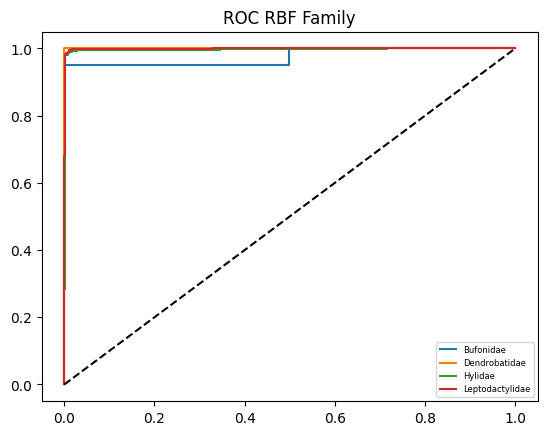

===== RBF Genus
               Adenomera  Ameerega  Dendropsophus  Hypsiboas  Leptodactylus  \
Adenomera           1239         0              1          5              0   
Ameerega               0       163              0          0              0   
Dendropsophus          1         0             92          0              0   
Hypsiboas              0         0              1        475              0   
Leptodactylus          0         0              0          2             79   
Osteocephalus          0         0              0          6              0   
Rhinella               0         0              0          1              0   
Scinax                 0         0              0          0              0   

               Osteocephalus  Rhinella  Scinax  
Adenomera                  1         0       0  
Ameerega                   0         0       0  
Dendropsophus              0         0       0  
Hypsiboas                  2         0       0  
Leptodactylus              

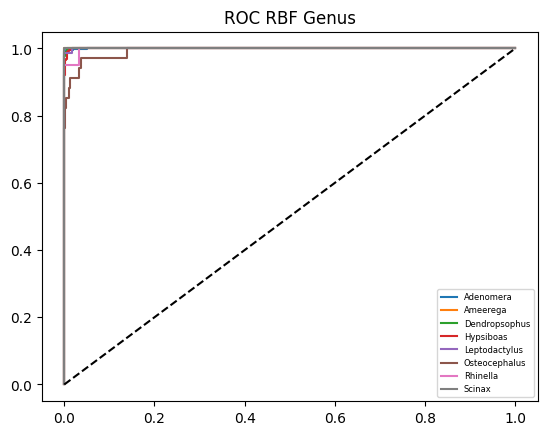

===== RBF Species
                        AdenomeraAndre  AdenomeraHylaedactylus  \
AdenomeraAndre                     198                       0   
AdenomeraHylaedactylus               0                    1043   
Ameeregatrivittata                   0                       0   
HylaMinuta                           0                       1   
HypsiboasCinerascens                 2                       0   
HypsiboasCordobae                    0                       2   
LeptodactylusFuscus                  0                       0   
OsteocephalusOophagus                0                       1   
Rhinellagranulosa                    0                       1   
ScinaxRuber                          0                       0   

                        Ameeregatrivittata  HylaMinuta  HypsiboasCinerascens  \
AdenomeraAndre                           0           1                     0   
AdenomeraHylaedactylus                   0           0                     0   
Ameeregatrivitt

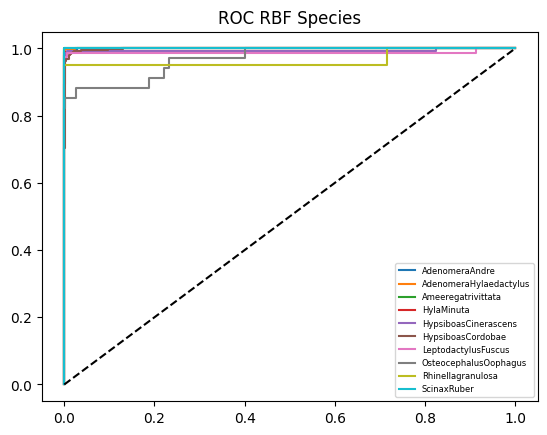

In [10]:
def label_report(gs, X_te, y_te, name):
    pred = gs.predict(X_te); classes = gs.classes_
    print("=====", name)
    print(pd.DataFrame(confusion_matrix(y_te, pred, labels=classes), index=classes, columns=classes))
    print(classification_report(y_te, pred, zero_division=0))
    Yb = label_binarize(y_te, classes=classes); s = gs.decision_function(X_te)
    print("AUC macro:", round(roc_auc_score(Yb, s, average="macro"), 4),
          "| micro:", round(roc_auc_score(Yb, s, average="micro"), 4))
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Yb[:, k], s[:, k]); plt.plot(fpr, tpr, label=c)
    plt.plot([0, 1], [0, 1], "k--"); plt.title(f"ROC {name}"); plt.legend(fontsize=6); plt.show()

for j, lab in enumerate(label_cols):
    label_report(rbf_models[("standardized", lab)], X_test, Y_test[:, j], f"RBF {lab}")

**How the metrics extend to multi-label.** I evaluated each label as its own multi-class problem. For every class, precision is "of the samples I called this class, how many were right", and recall is "of the true samples of this class, how many I found". The ROC curve and AUC are computed one class against all others. To get one number per label, I averaged over classes. Macro averages the classes equally. Micro pools all samples, so big classes dominate.

**Results (Gaussian SVM, standardized)**

| Label   | Macro AUC | Micro AUC |
| ------- | --------- | --------- |
| Family  | 0.9928    | 0.9989    |
| Genus   | 0.9988    | 0.9997    |
| Species | 0.9912    | 0.9978    |

**Observations**

- All AUCs are above 0.99, so the classifiers rank the classes almost perfectly.
- Micro AUC is higher than macro because rare classes are harder, and macro counts them as much as large ones.
- The weakest class is OsteocephalusOophagus (recall 0.82). Bufonidae and Rhinella have recall 0.95, but they have only 20 test samples each, so one mistake changes the number.
- Almost all errors are between closely related groups: Hylidae vs Leptodactylidae, and Osteocephalus vs Hypsiboas.


## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set


### (a) Use k-means clustering


In [11]:
Y_df = pd.DataFrame(Y, columns=label_cols)

def choose_k(X, seed, ks=range(2, 51)):
    best_k, best_s = None, -1
    for k in ks:
        lab = KMeans(n_clusters=k, n_init=3, random_state=seed).fit_predict(X)
        s = silhouette_score(X, lab, sample_size=2000, random_state=seed)
        if s > best_s: best_k, best_s = k, s
    return best_k

seed = 0
k_star = choose_k(X, seed)
clusters = KMeans(n_clusters=k_star, n_init=10, random_state=seed).fit_predict(X)
print("chosen k:", k_star)

chosen k: 4


**What I did.** I ran k-means on all 7195 samples (no train/test split). I chose k from 2 to 50 with the silhouette score, which measures how well-separated the clusters are. k = 1 is skipped because silhouette is not defined for one cluster. To keep it fast, I scored on a random subset of 2000 points.

**Result.** For the first run, k = 4. Across the 50 Monte Carlo runs, k was 4 in 41 runs, 3 in 3 runs, 5 in 2 runs and 6 in 4 runs.


### (b) Determine which family is the majority


In [12]:
def majority_triplets(clusters, Y_df):
    maj = {c: Y_df[c].groupby(clusters).agg(lambda s: s.mode().iloc[0]) for c in label_cols}
    pred = np.column_stack([maj[c].loc[clusters].values for c in label_cols])
    return pd.DataFrame(maj), pred

maj_table, pred = majority_triplets(clusters, Y_df)
maj_table["size"] = pd.Series(clusters).value_counts().sort_index()
maj_table

,Family,Genus,Species,size
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3568
1,Hylidae,Hypsiboas,HypsiboasCordobae,1982
2,Dendrobatidae,Ameerega,Ameeregatrivittata,1031
3,Hylidae,Hypsiboas,HypsiboasCinerascens,614


**What I did.** For each cluster I counted the true labels inside it and took the most common Family, Genus and Species.

| Cluster | Size | Family          | Genus     | Species                |
| ------- | ---- | --------------- | --------- | ---------------------- |
| 0       | 3568 | Leptodactylidae | Adenomera | AdenomeraHylaedactylus |
| 1       | 1982 | Hylidae         | Hypsiboas | HypsiboasCordobae      |
| 2       | 1031 | Dendrobatidae   | Ameerega  | Ameeregatrivittata     |
| 3       | 614  | Hylidae         | Hypsiboas | HypsiboasCinerascens   |

**Observations**

- With 4 clusters, only 3 of the 4 families, 3 of the 8 genera and 4 of the 10 species can ever be predicted. Rare classes such as Bufonidae are never the majority anywhere, so their samples are always counted wrong.
- Clusters 1 and 3 have the same family and genus but different species, so k-means split the Hypsiboas calls into two groups.


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss


In [ ]:
n_runs = 50
res, ks = [], []
for r in range(n_runs):
    k = choose_k(X, r); ks.append(k)
    cl = KMeans(n_clusters=k, n_init=10, random_state=r).fit_predict(X)
    _, pr = majority_triplets(cl, Y_df)
    sc_ = multilabel_scores(Y, pr)
    res.append([sc_["hamming_distance"], sc_["hamming_score"], sc_["hamming_loss"]])
res = pd.DataFrame(res, columns=["hamming_distance", "hamming_score", "hamming_loss"])
print(res.agg(["mean", "std"]).round(4))
print("chosen k per run:", ks)

**What I did.** I repeated the full procedure 50 times with different random seeds: choose k, run k-means, give every sample its cluster's majority labels, then compare with the true labels.

**Results (mean ± standard deviation over 50 runs)**

| Metric           | Mean   | Std    |
| ---------------- | ------ | ------ |
| Hamming distance | 0.6657 | 0.0813 |
| Hamming score    | 0.7781 | 0.0271 |
| Hamming loss     | 0.2219 | 0.0271 |

**Observations**

- On average about 22% of the label answers are wrong (0.67 wrong labels out of 3 per sample). The supervised Gaussian SVM got about 0.9% wrong.
- Clustering is unsupervised and the silhouette score prefers a few compact clusters (usually 4), while the data has 10 species. A cluster can only output one answer, so every rare class loses.
- The standard deviation is small because k was 4 in most runs. The rest comes from random initialization and the runs where k was 3, 5 or 6.


## 3. ISLR 12.6.2


In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

D = np.array([[0, .3, .4, .7],
              [.3, 0, .5, .8],
              [.4, .5, 0, .45],
              [.7, .8, .45, 0]])

for m in ["complete", "single"]:
    Z = linkage(squareform(D), method=m)
    plt.figure(figsize=(4, 3)); dendrogram(Z, labels=[1, 2, 3, 4]); plt.title(m + " linkage"); plt.show()
    print(m, "2 clusters:", fcluster(Z, t=2, criterion="maxclust"))

      hamming_distance  hamming_score  hamming_loss
mean            0.6657         0.7781        0.2219
std             0.0813         0.0271        0.0271
chosen k per run: [4, 4, 4, 4, 5, 4, 4, 4, 6, 4, 4, 4, 4, 4, 4, 4, 4, 6, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 6, 4, 4, 4, 4, 4, 4, 4, 3, 4, 4, 4, 4, 5, 4, 4, 3, 3, 6, 4]


Dissimilarity between observations: d(1,2)=0.3, d(1,3)=0.4, d(1,4)=0.7, d(2,3)=0.5, d(2,4)=0.8, d(3,4)=0.45. Complete linkage measures the distance between two clusters by their farthest pair. Single linkage uses their closest pair.

**(a) Complete linkage.** The smallest distance is 0.3, so 1 and 2 fuse first. Then d({1,2},3) = max(0.4, 0.5) = 0.5, d({1,2},4) = max(0.7, 0.8) = 0.8, and d(3,4) = 0.45. The smallest is 0.45, so 3 and 4 fuse next. Finally {1,2} and {3,4} fuse at height max(0.4, 0.5, 0.7, 0.8) = 0.8.

**(b) Single linkage.** 1 and 2 fuse at 0.3. Then d({1,2},3) = min(0.4, 0.5) = 0.4, d({1,2},4) = min(0.7, 0.8) = 0.7, and d(3,4) = 0.45. So 3 joins {1,2} at 0.4. Finally 4 joins at min(0.7, 0.8, 0.45) = 0.45.

**(c)** Cutting the complete-linkage tree to get two clusters gives {1,2} and {3,4}.

**(d)** Cutting the single-linkage tree to get two clusters gives {1,2,3} and {4}.

**(e)** At every fusion the two branches can be swapped (like turning a hanging mobile) without changing the tree. For example, leaf order 2,1,4,3 gives the same tree as 1,2,3,4. Only the height of each fusion and which observations are joined carry meaning, not the left-to-right order of leaves.
